In [1]:
%pip install pygbif pandas seaborn plotly geopandas

  Using cached pyogrio-0.13.0-cp311-abi3-win_amd64.whl.metadata (6.0 kB)
Using cached pyogrio-0.13.0-cp311-abi3-win_amd64.whl (23.8 MB)
   ---------------------------------------- 0.0/6.7 MB ? eta -:--:--
   ---------------------------------------- 6.7/6.7 MB 41.4 MB/s  0:00:00
   ---------------------------------------- 0.0/1.8 MB ? eta -:--:--
   ---------------------------------------- 1.8/1.8 MB 55.1 MB/s  0:00:00

   ---------------------------------------- 0/4 [shapely]
   ---------- ----------------------------- 1/4 [pyproj]
   -------------------- ------------------- 2/4 [pyogrio]
   -------------------- ------------------- 2/4 [pyogrio]
   -------------------- ------------------- 2/4 [pyogrio]
   ------------------------------ --------- 3/4 [geopandas]
   ---------------------------------------- 4/4 [geopandas]

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
from pygbif import occurrences as occ

TARGET_SPECIES = {
    "cheetah": "Acinonyx jubatus",
    "lion": "Panthera leo",
    "leopard": "Panthera pardus",
    "elephant": "Loxodonta africana",
    "buffalo": "Syncerus caffer",
    #"black_rhino": "Diceros bicornis", -- Remove rhino to not contribute for fortive hunt
}

TANZANIA_BBOX = "POLYGON((34.5 -4.5, 36.5 -4.5, 36.5 -1.5, 34.5 -1.5, 34.5 -4.5))"

all_records = []

for common_name, sci_name in TARGET_SPECIES.items():
    res = occ.search(
        scientificName=sci_name,
        geometry=TANZANIA_BBOX,
        hasCoordinate=True,
        basisOfRecord="HUMAN_OBSERVATION",
        limit=300,
    )
    records = res.get("results", [])
    for r in records:
        r["target_label"] = common_name
    all_records.extend(records)

df = pd.DataFrame(all_records)

In [3]:
nan_count = df["eventDate"].isna().sum()
print(nan_count)

0


In [4]:
df_simplified = df[["target_label", "decimalLatitude", "decimalLongitude", "coordinateUncertaintyInMeters", "occurrenceStatus", "countryCode", "eventDate"]]

df_simplified = df_simplified.rename(
    columns={
        "target_label": "common_name",
        "decimalLatitude": "latitude",
        "decimalLongitude": "longitude",
        "coordinateUncertaintyInMeters": "spatial_precision_radius",
        "occurrenceStatus": "occurrence_status",
        "countryCode": "country_code",
        "eventDate": "event_date",
    }
)

df_simplified["event_date"] = pd.to_datetime(
    df_simplified["event_date"], format="mixed", errors="coerce", utc=True
)

df_simplified.head()

,common_name,latitude,longitude,spatial_precision_radius,occurrence_status,country_code,event_date
0,cheetah,-4.114665,36.057254,47053.0,PRESENT,TZ,2026-01-05 16:43:00+00:00
1,cheetah,-1.596493,35.384591,31446.0,PRESENT,KE,2026-01-06 07:29:03+00:00
2,cheetah,-2.452807,34.961872,31436.0,PRESENT,TZ,2026-01-12 09:49:17+00:00
3,cheetah,-3.498304,34.795777,31422.0,PRESENT,TZ,2026-01-06 11:06:00+00:00
4,cheetah,-3.138127,34.960164,31428.0,PRESENT,TZ,2026-01-13 17:02:51+00:00


In [5]:
nat_indices = df_simplified[df_simplified["event_date"].isna()].index

print(f"Count of unparsed dates: {len(nat_indices)}")

Count of unparsed dates: 0


In [6]:
df_simplified["event_date_daily"] = pd.to_datetime(
    df_simplified["event_date"].dt.date
)

In [7]:
plot_df = df_simplified.dropna(
    subset=["event_date_daily", "country_code", "common_name"]
).copy()

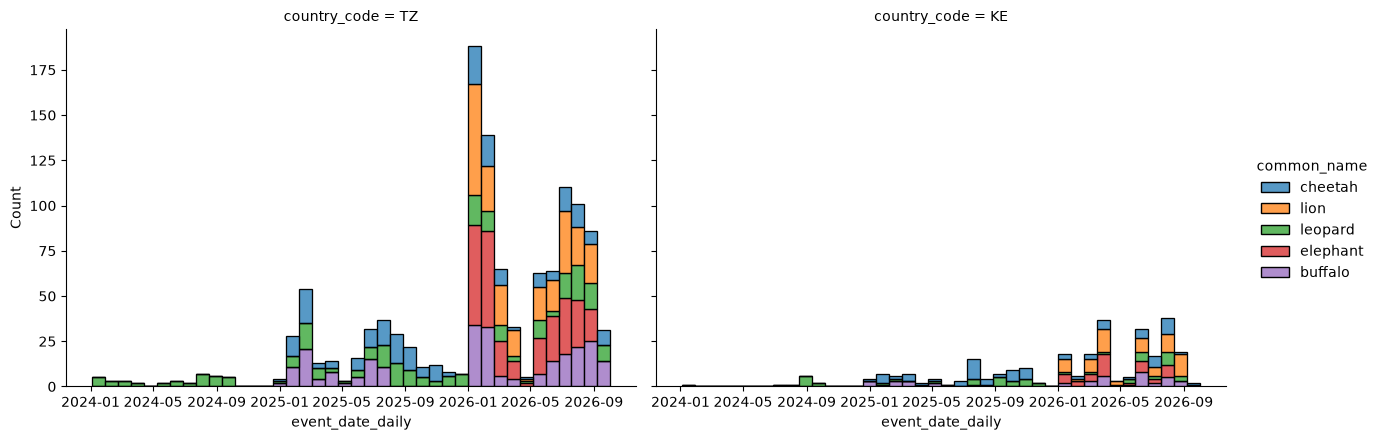

In [8]:
import seaborn as sns

g = sns.displot(
    data=plot_df,
    x="event_date_daily",
    hue="common_name",
    col="country_code",
    multiple="stack",
    kind="hist",
    bins=40,
    height=4.5,
    aspect=1.4,
)

In [9]:
import plotly.express as px

plot_df = df_simplified.dropna(
    subset=["latitude", "longitude", "country_code", "common_name"]
).copy()

plot_df["event_date_str"] = plot_df["event_date"].dt.strftime(
    "%Y-%m-%d %H:%M:%S"
)

In [10]:
fig = px.scatter_map(
    plot_df,
    lat="latitude",
    lon="longitude",
    color="common_name",
    hover_name="common_name",
    hover_data={
        "latitude": ":.4f",
        "longitude": ":.4f",
        "spatial_precision_radius": True,
        "event_date_str": True,
        "country_code": False,
    },
    zoom=6,
    height=600,
    map_style="carto-positron",
    title="Wildlife Presence Observations (GBIF)",
)

fig.update_layout(margin={"r": 0, "t": 40, "l": 0, "b": 0})
fig.show()


## Basics of EDA and concepts:

- *Sampling bias*: Data records where people looked, not where the animals actually are.
  - People are driving along main safari, they take a photo of an animal and upload it.
  - Deep in the bush where no tourists exists, nobody is taking photos.
  - If we create machine learning models based on this data, the model will wrongly assume that roads attract lions, which is not correct. Because 95% of lion sightings are within 50 meters of a dirt road. This is not the true animal habit.
- *Spatial Clumping*: Too many data points are piled up in the exact same coordinates or tiny micro-areas.
  - One animal, 30 tourists. Basically muiltiple sightings of the same animal, it doesn't mean that the animal was saw multiple times in different time spans.
  - Another usecase is that, the dataset doesn't have fine GPS coordinates. So, by error, it just says, well the animals is at this center point.
  - For machine learning models:
    - Violation of independence: Machine learning assumes each row of data is an independent observation.
    - Overfitting: The model sees 30 points at (x, y) and treats that single spot as a 30 times more significant than the rest of the park.
  - How to fix these problems?
    - Spatial deduplication: Impoise a minimum distance filter - distance between points.
    - Coordinate precision filtering: If the uncertainty radius is too big, its not relevant.
-

## Data Quality Fixes

In [12]:
# Drop records where GPS uncertainty radius exceeds 5 km — too imprecise to be useful
MAX_UNCERTAINTY_METERS = 5_000

df_clean = df_simplified.dropna(subset=["spatial_precision_radius"]).copy()
df_clean = df_clean[df_clean["spatial_precision_radius"] <= MAX_UNCERTAINTY_METERS]

print(f"Before precision filter : {len(df_simplified):>5} records")
print(f"After  precision filter : {len(df_clean):>5} records")
print(f"Dropped                 : {len(df_simplified) - len(df_clean):>5} records")

Before precision filter :  1500 records
After  precision filter :     4 records
Dropped                 :  1496 records


In [13]:
import geopandas as gpd

# ADR-0001: reproject to EPSG:32736 (UTM 36S, meters) before any distance operation
GRID_SIZE_METERS = 1_000  # 1 km grid

gdf = gpd.GeoDataFrame(
    df_clean,
    geometry=gpd.points_from_xy(df_clean["longitude"], df_clean["latitude"]),
    crs="EPSG:4326",
).to_crs("EPSG:32736")

gdf["_x_grid"] = (gdf.geometry.x / GRID_SIZE_METERS).round()
gdf["_y_grid"] = (gdf.geometry.y / GRID_SIZE_METERS).round()

# Within each grid cell keep the most recent sighting
df_dedup = (
    gdf
    .sort_values("event_date", ascending=False)
    .drop_duplicates(subset=["common_name", "_x_grid", "_y_grid"])
    .drop(columns=["_x_grid", "_y_grid", "geometry"])
    .reset_index(drop=True)
)

print(f"Before spatial dedup : {len(df_clean):>5} records")
print(f"After  spatial dedup : {len(df_dedup):>5} records")
print(f"Dropped              : {len(df_clean) - len(df_dedup):>5} records")

Before spatial dedup :     4 records
After  spatial dedup :     3 records
Dropped              :     1 records


In [14]:
fig = px.scatter_map(
    df_dedup.dropna(subset=["latitude", "longitude"]),
    lat="latitude",
    lon="longitude",
    color="common_name",
    hover_name="common_name",
    hover_data={
        "latitude": ":.4f",
        "longitude": ":.4f",
        "spatial_precision_radius": True,
        "country_code": True,
    },
    zoom=6,
    height=600,
    map_style="carto-positron",
    title="Wildlife Sightings — After Quality Filters (precision ≤ 5 km, spatially deduplicated ~1 km)",
)

fig.update_layout(margin={"r": 0, "t": 40, "l": 0, "b": 0})
fig.show()